Questo notebookl andalizza il dataset costruito nel Notebook01 per capire se è adatto alla costruzione di un sistema di raccomandazione.
In particolare analizzare la sparsità dei dati.

In [2]:
#Se mancano pacchetti, esegui questa cella una sola volta.
%pip install -q "datasets==3.6.0" pandas pyarrow requests tqdm
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
from pathlib import Path
import json
import math
import warnings #gestire warnings
import numpy as np 
import pandas as pd
import pyarrow.parquet as pq 
import matplotlib.pyplot as plt 

warnings.filterwarnings("ignore", category=FutureWarning) #nasconde avvisi per output meno rumoroso
#impostazioni di pandas
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.6f}")  

In [4]:
#percorsi
CATEGORY="Electronics"

PROJECT_ROOT = Path("..").resolve() if (Path("..") / "data").exists() else Path(".").resolve()  #determina automaticamente la cartella principale del progetto
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "electronics_intersection" #percorso dati notebook01
ANALYSIS_DIR = PROCESSED_DIR / "analysis" #dove salvare risultati notebook02
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True) #la crea se non esiste già

#percorsi dei file prodotti nel notebook01
ITEMS_PATH = PROCESSED_DIR / "items.parquet"
QA_PATH = PROCESSED_DIR / "qa.parquet"
RATINGS_PATH = PROCESSED_DIR / "ratings.parquet"
SUMMARY_PATH = PROCESSED_DIR / "summary.json"

#dizionario per associare nome leggibile ad ogni percorso
paths={
    "items": ITEMS_PATH,
    "qa": QA_PATH,
    "ratings":RATINGS_PATH,
    "summary": SUMMARY_PATH,
}
#controllo dei percorsi
print("Project root:", PROJECT_ROOT)
print("Processed dir:", PROCESSED_DIR)
print("Analysis dir:", ANALYSIS_DIR)
for name, path in paths.items():
    print(f"{name:8s}->{path} | exists={path.exists()}")

Project root: C:\Users\arsid\Desktop\Tesi-ecommerce
Processed dir: C:\Users\arsid\Desktop\Tesi-ecommerce\data\processed\electronics_intersection
Analysis dir: C:\Users\arsid\Desktop\Tesi-ecommerce\data\processed\electronics_intersection\analysis
items   ->C:\Users\arsid\Desktop\Tesi-ecommerce\data\processed\electronics_intersection\items.parquet | exists=True
qa      ->C:\Users\arsid\Desktop\Tesi-ecommerce\data\processed\electronics_intersection\qa.parquet | exists=True
ratings ->C:\Users\arsid\Desktop\Tesi-ecommerce\data\processed\electronics_intersection\ratings.parquet | exists=True
summary ->C:\Users\arsid\Desktop\Tesi-ecommerce\data\processed\electronics_intersection\summary.json | exists=True


In [5]:
#dati attesi mancanti, in caso avvisa di eseguire prima notebook01
missing =[str(path) for path in paths.values() if not path.exists()]
if missing:
    raise FileNotFoundError(
        "mancano cerci file del notebook01: \n"
        + "\n".join(missing)+ "\n\nEsegui prima il notebook: 01_prepare_electronics_intersection.ipynb"
    )

In [6]:
#lettura dei metadata dei parquet
def parquet_info(path: Path)->dict:
    pf=pq.ParquetFile(path)
    return{
        "file":path.name,
        "rows":pf.metadata.num_rows,
        "row_groups":pf.metadata.num_row_groups,
        "columns": len(pf.schema_arrow.names),
        "column_names": ", ".join(pf.schema_arrow.names),
    }

parquet_infos=pd.DataFrame([
    parquet_info(ITEMS_PATH),
    parquet_info(QA_PATH),
    parquet_info(RATINGS_PATH),
])

parquet_infos

,file,rows,row_groups,columns,column_names
0,items.parquet,22974,1,12,"parent_asin, title, category, avg_rating, num_ratings, price, store, features_json, description_json, categories_jso..."
1,qa.parquet,180976,1,8,"qa_id, parent_asin, question, answer, questionType, answerType, answerTime, unixTime"
2,ratings.parquet,3484401,18,6,"user_id, parent_asin, asin, rating, timestamp, verified_purchase"


In [7]:
#controlliamo summary.json
if SUMMARY_PATH.exists():
    summary=json.loads(SUMMARY_PATH.read_text(encoding="utf-8"))
    display(pd.DataFrame([summary]).T.rename(columns={0: "rows_from_summary_json"}))
else:
    summary={}
    print("summary.json non trovato. Ricarica notebook 02")

,rows_from_summary_json
items,22974
qa,180976
ratings,3484401


In [8]:
#caricamento dei dati
def parquet_columns(path: Path)-> list[str]: #funzione che restituisce i nomi delle colonne
    return pq.ParquetFile(path).schema_arrow.names

def columns_keep(path: Path, wanted: list[str])-> list[str]: #funzione che tiene solo le colonne richieste
    available=set(parquet_columns(path))
    return [col for col in wanted if col in available]

items_df=pd.read_parquet(ITEMS_PATH)
qa_df=pd.read_parquet(QA_PATH)

wanted_rating_columns=[
    "user_id","parent_asin","asin","rating","timestamp","verified_purchase",
    "review_title","review_text",#se presenti le colonne testuali, in base a cosa si è scelto nel notebook 01
]

rating_columns=columns_keep(RATINGS_PATH,wanted_rating_columns)
ratings_df=pd.read_parquet(RATINGS_PATH,columns=rating_columns)

print("items_df:", items_df.shape)
print("qa_df:", qa_df.shape)
print("ratings_df:", ratings_df.shape)
print("Colonne rating caricate:", rating_columns)

items_df: (22974, 12)
qa_df: (180976, 8)
ratings_df: (3484401, 6)
Colonne rating caricate: ['user_id', 'parent_asin', 'asin', 'rating', 'timestamp', 'verified_purchase']


In [9]:
display(items_df.head(3))
display(qa_df.head(3))
display(ratings_df.head(3))

,parent_asin,title,category,avg_rating,num_ratings,price,store,features_json,description_json,categories_json,details_json,image_url
0,B00CFGZAT8,"Dock Audio Extender Adapter Converter Cable for iPod iPhone 4 4S iPhone 5 5S iPad, Samsung & Other Smart Phones",Portable Audio & Accessories,3.600000,45,NaN,iteck,[],[],"[""Electronics"", ""Computers & Accessories"", ""Tablet Accessories"", ""Chargers & Adapters""]","""{\""Brand Name\"": \""iTeck\"", \""Item Weight\"": \""0.8 ounces\"", \""Package Dimensions\"": \""6 x 4 x 0.3 inches; 0.8 Ounc...",https://m.media-amazon.com/images/I/41uTuqlHDSL._AC_.jpg
1,B00BGFTSGU,GGS Swivi HD DSLR LCD Universal Foldable Viewfinder Version II with 3.0X Magnification,Camera & Photo,3.700000,52,149.000000,Swivi,[],[],"[""Electronics"", ""Camera & Photo"", ""Accessories"", ""Viewfinders""]","""{\""Product Dimensions\"": \""3.8 x 4.3 x 6.9 inches\"", \""Item Weight\"": \""0.705 ounces\"", \""Item model number\"": \""Sw...",https://m.media-amazon.com/images/I/41BUv5PjMDL._AC_.jpg
2,B00AZOIG9I,BM Premium 2-Pack of NP-85 Batteries and Charger Kit for FujiFilm FinePix S1 SL240 SL260 SL280 SL300 SL305 SL1000 Di...,Camera & Photo,4.700000,345,22.990000,BM Premium,"[""NP85 Li-ion Battery for FujiFilm FinePix SL240 SL260 SL280 SL300 SL305 SL1000 Digital Camera"", ""Battery Specificat...","[""Bring your digital camera back to life with a new battery. Make sure you never miss another once-in-a-lifetime mom...","[""Electronics"", ""Camera & Photo"", ""Accessories"", ""Batteries & Chargers"", ""Batteries"", ""Camera Batteries""]","""{\""Package Dimensions\"": \""6.46 x 3.94 x 1.85 inches\"", \""Item Weight\"": \""6.7 ounces\"", \""Item model number\"": \""N...",https://m.media-amazon.com/images/I/71fbU-87TxL._AC_SL1500_.jpg


,qa_id,parent_asin,question,answer,questionType,answerType,answerTime,unixTime
0,0,0594033926,Is this cover the one that fits the old nook color? Which I believe is 8x5.,Yes this fits both the nook color and the same-shaped nook tablet,yes/no,Y,"Dec 27, 2013","1,388,131,200.000000"
1,1,0594033926,Does it fit Nook GlowLight?,No. The nook color or color tablet,yes/no,N,"Jan 5, 2015","1,420,444,800.000000"
2,2,0594033926,Would it fit Nook 1st Edition? 4.9in x 7.7in ?,"I don't think so. The nook color is 5 x 8 so not sure anything smaller would stay locked in, but would be close.",open-ended,NaN,2 days ago,NaN


,user_id,parent_asin,asin,rating,timestamp,verified_purchase
0,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,B0047T79VS,B0047T79VS,3.000000,1344406083000,True
1,AFTC6ZR5IKNRDG5JCPVNVMU3XV2Q,B001FWYGJS,B001FWYGJS,4.000000,1427592277000,True
2,AHITBJSS7KYUBVZPX7M2WJCOIVKQ,B00BHC7ZTE,B00BHC7ZTE,5.000000,1432342265000,True


In [10]:
#controlli generali di coerenza
def pct(numerator, denominator): #funzione che useremo anche dopo per calcolare la percentuale
    if denominator == 0:
        return np.nan
    return numerator/denominator *100

items_set=set(items_df["parent_asin"].dropna()) #insieme parentasin nei metadati, droppando valori nulli
ratings_items_set=set(ratings_df["parent_asin"].dropna()) #insieme parentasin dei rating
qa_items_set=set(qa_df["parent_asin"].dropna()) #insieme parentasin qa
#dizionario con statistiche generali del dataset
basic_stats={
    "num_product_items": items_df["parent_asin"].nunique(), #conta quanti prodotti unici nella tabella items
    "num_rating_rows": len(ratings_df), #conta quante righe di rating presenti
    "num_users":ratings_df["user_id"].nunique(dropna=True), #quanti utenti unici compaiono nei rating
    "num_products_with_ratings": ratings_df["parent_asin"].nunique(dropna=True), #quanti prodotti distinti hanno almeno un rating
    "num_qa_rows":len(qa_df), #quante righe di domande/risposte presenti
    "num_products_with_qa": qa_df["parent_asin"].nunique(dropna=True), #quanti prodotti distinti hanno almeno una domanda/risposta
    "items_parent_asin_unique": bool(items_df["parent_asin"].is_unique), #controlla se parent_asin è unico nella tabella items
    "ratings_products_all_in_items": ratings_items_set.issubset(items_set), #verifica se tutti i prodotti nei rating sono presenti anche nei metadati items
    "qa_products_all_in_items": qa_items_set.issubset(items_set), #controlla se tutti prodotti qa sono presenti anche nei metadati items
    "items_with_rating_pct": pct(len(items_set & ratings_items_set), len(items_set)), #calcola percentuale di prodotti items che hanno almeno un rating
    "items_with_qa_pct": pct(len(items_set & qa_items_set), len(items_set)), #calcola percentuale di prodotti items che hanno almeno una riga QA
}

basic_stats_df=pd.DataFrame.from_dict(basic_stats, orient="index", columns=["value"]) #converte dizionario delle stats generali in tabella pandas
display(basic_stats_df)

basic_stats_df.to_csv(ANALYSIS_DIR/"notebook02_basic_stats.csv")

,value
num_product_items,22974
num_rating_rows,3484401
num_users,2434619
num_products_with_ratings,22974
num_qa_rows,180976
num_products_with_qa,22974
items_parent_asin_unique,True
ratings_products_all_in_items,True
qa_products_all_in_items,True
items_with_rating_pct,100.000000


In [11]:
#se alcuni prodotti sono presenti nei ratings ma non in items (se esce 0 perfetto)
missing_rating_products = ratings_items_set - items_set
#se alcuni prodotti sono presenti nel QA ma assenti in items (se esce 0 perfetto)
missing_qa_products = qa_items_set - items_set
print("Prodotti in ratings ma non in items:", len(missing_rating_products))
print("Prodotti in qa ma non in items:", len(missing_qa_products))
if missing_rating_products:
    print("Esempi ratings fuori items:", list(missing_rating_products)[:5])
if missing_qa_products:
    print("Esempi QA fuori items:", list(missing_qa_products)[:5])

Prodotti in ratings ma non in items: 0
Prodotti in qa ma non in items: 0


In [12]:
#ora bisogna controllare la qualità di questi dati
important_columns={ #dizionario con colonne importanti da controllare
    "items": ["parent_asin","title","category"],
    "qa": ["parent_asin","question","answer"],
    "ratings": ["user_id","parent_asin","rating"],
}
null_rows=[]
#scorriamo le tabelle e colonne da controllare
for df_name, cols in important_columns.items():
    df={"items":items_df, "qa":qa_df, "ratings":ratings_df}[df_name]
    for col in cols:
        if col in  df.columns:
            null_rows.append({
                "table":df_name,
                "column":col,
                "null_count":int(df[col].isna().sum()), #conta quanti valori nulli presenti nella colonna
                "null_pct": pct(int(df[col].isna().sum()), len(df)), #conta la percentuale di valori nulli nella colonna
            })

nulls_df=pd.DataFrame(null_rows)
nulls_df


,table,column,null_count,null_pct
0,items,parent_asin,0,0.000000
1,items,title,0,0.000000
2,items,category,0,0.000000
3,qa,parent_asin,0,0.000000
4,qa,question,0,0.000000
5,qa,answer,0,0.000000
6,ratings,user_id,0,0.000000
7,ratings,parent_asin,0,0.000000
8,ratings,rating,0,0.000000


In [ ]:
#vediamo se ci sono rating nulli
invalid_rating_mask= ratings_df["rating"].isna() | ~ratings_df["rating"].between(1,5)
invalid_ratings=ratings_df.loc[invalid_rating_mask]
print("Rating nulli o fuori scala:", len(invalid_ratings))
if len(invalid_ratings)>0:
    display(invalid_ratings.head())


Rating nulli o fuori scala: 0


In [18]:
#calcoliamo distribuzione dei voti
rating_dist=(
    ratings_df["rating"].value_counts(dropna=False).sort_index().rename_axis("rating").reset_index(name="count")
)
rating_dist["pct"]=rating_dist["count"]/len(ratings_df)*100 #percentuale di ogni voto sul tot
rating_dist

,rating,count,pct
0,1.000000,399404,11.462630
1,2.000000,195919,5.622745
2,3.000000,264586,7.593443
3,4.000000,573679,16.464207
4,5.000000,2050813,58.856974


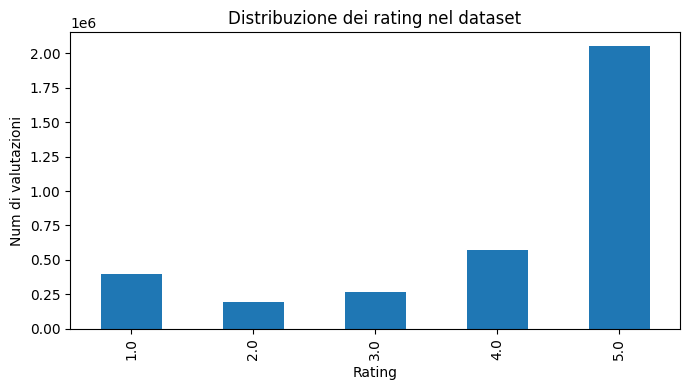

In [ ]:
#schema dei dati visti sopra sui rating
plt.figure(figsize=(7,4))
rating_dist.dropna(subset=["rating"]).plot(
    x="rating",y="count",kind="bar",legend=False,ax=plt.gca()
)
plt.title("Distribuzione dei rating nel dataset")
plt.xlabel("Rating")
plt.ylabel("Num di valutazioni")
plt.tight_layout()
plt.show()

In [ ]:
#funzione per capire se timestamp sono in sec o millisec
def timestamp_un(series:pd.Series)->str | None:
    values=pd.to_numeric(series.dropna(), errors)